# 01 · FD001 数据探索

**要回答的问题**

1. 每个传感器测的是什么？
2. 哪些特征没有用，可以去掉？
3. 发动机退化时传感器怎么变？从什么时候开始变？

**防泄漏约定**：这里只分析**训练集**。官方测试集只看每台发动机的轨迹长度（用来确定滑动窗口的上限），不看传感器读数，也不读 `RUL_FD001.txt` 答案。

图表文字用英文，这样换一台没有中文字体的机器也不会显示成方块。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rul.data import SENSOR_COLUMNS, SETTING_COLUMNS, load_trajectories

BLUE, ORANGE, GRAY, INK = "#2a78d6", "#eb6834", "#c9c8c2", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "text.color": INK, "axes.labelcolor": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.edgecolor": GRAY,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
pd.set_option("display.max_rows", 40)

train = load_trajectories("FD001", "train")
test_lengths = load_trajectories("FD001", "test").groupby("unit")["cycle"].max()

# RUL = 该发动机最后一个周期 - 当前周期。正式的标签函数和测试在 T-004 放进 src/。
train["rul"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]


def spearman(a, b):
    """Spearman 相关 = 排名后的 Pearson 相关。只看单调关系，不要求线性，也不需要 scipy。"""
    return a.rank().corr(b.rank())

## 1. 数据结构

每行是一台发动机的一个运行周期。训练轨迹一直记录到故障，所以最后一行的 RUL 就是 0。

In [2]:
life = train.groupby("unit")["cycle"].max()
print("训练集形状:", train.drop(columns="rul").shape, "| 发动机台数:", train["unit"].nunique())
print("周期是否连续:", bool((train.groupby("unit")["cycle"].diff().dropna() == 1).all()))
print("重复 (unit, cycle):", int(train.duplicated(["unit", "cycle"]).sum()))

pd.DataFrame({"train: cycles to failure": life.describe(),
              "test: cycles observed": test_lengths.describe()}).round(1)

训练集形状: (20631, 26) | 发动机台数: 100
周期是否连续: True
重复 (unit, cycle): 0


,train: cycles to failure,test: cycles observed
count,100.0,100.0
mean,206.3,131.0
std,46.3,53.6
min,128.0,31.0
25%,177.0,88.8
50%,199.0,133.5
75%,229.2,164.2
max,362.0,303.0


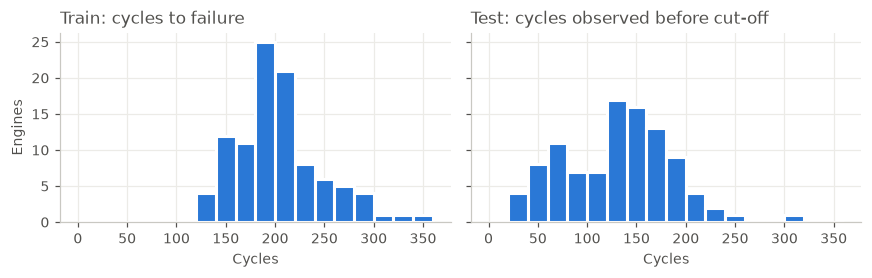

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(8, 2.6), sharey=True)
bins = np.arange(0, 380, 20)
for ax, values, title in [(axes[0], life, "Train: cycles to failure"),
                          (axes[1], test_lengths, "Test: cycles observed before cut-off")]:
    ax.hist(values, bins=bins, color=BLUE, edgecolor="white", linewidth=2)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Cycles")
axes[0].set_ylabel("Engines")
plt.tight_layout()

**发现**

- 数据很干净：周期连续，没有重复行。
- 训练集寿命 128–362 个周期，差异很大，所以不能靠“已运行多少周期”直接推算寿命。
- 测试集最短轨迹只有 **31 个周期**，这决定了滑动窗口特征的设计：窗口超过 31 时，这些发动机凑不满一个窗口，需要允许窗口不满（T-006）。

## 2. 传感器含义

官方 `readme.txt` 只写了“sensor measurement 1–21”，没有说明含义。下表的名称来自 C-MAPSS 文献惯用的传感器表（通常引用 Saxena et al., 2008）。我核对了两篇转引该表的论文（arXiv 2605.02507、2503.07854），但**没有读到 Saxena 原文**，写 README 前应再查一次原文。

下表最后一列是训练集的实际均值，可以和含义互相印证。例如 sensor_1 恒为 518.67 °R，约等于海平面标准气温；sensor_5 恒为 14.62 psia，接近海平面气压。这和 readme 写的 FD001 工况 “ONE (Sea Level)” 一致。

In [4]:
SENSORS = [
    ("T2", "Total temperature at fan inlet", "°R"),
    ("T24", "Total temperature at LPC outlet", "°R"),
    ("T30", "Total temperature at HPC outlet", "°R"),
    ("T50", "Total temperature at LPT outlet", "°R"),
    ("P2", "Pressure at fan inlet", "psia"),
    ("P15", "Total pressure in bypass duct", "psia"),
    ("P30", "Total pressure at HPC outlet", "psia"),
    ("Nf", "Physical fan speed", "rpm"),
    ("Nc", "Physical core speed", "rpm"),
    ("epr", "Engine pressure ratio (P50/P2)", "-"),
    ("Ps30", "Static pressure at HPC outlet", "psia"),
    ("phi", "Ratio of fuel flow to Ps30", "pps/psi"),
    ("NRf", "Corrected fan speed", "rpm"),
    ("NRc", "Corrected core speed", "rpm"),
    ("BPR", "Bypass ratio", "-"),
    ("farB", "Burner fuel-air ratio", "-"),
    ("htBleed", "Bleed enthalpy", "-"),
    ("Nf_dmd", "Demanded fan speed", "rpm"),
    ("PCNfR_dmd", "Demanded corrected fan speed", "rpm"),
    ("W31", "HPT coolant bleed", "lbm/s"),
    ("W32", "LPT coolant bleed", "lbm/s"),
]
sensor_table = pd.DataFrame(SENSORS, columns=["symbol", "meaning", "unit"], index=SENSOR_COLUMNS)
sensor_table["train mean"] = train[SENSOR_COLUMNS].mean().round(3)
sensor_table

,symbol,meaning,unit,train mean
sensor_1,T2,Total temperature at fan inlet,°R,518.670
sensor_2,T24,Total temperature at LPC outlet,°R,642.681
sensor_3,T30,Total temperature at HPC outlet,°R,1590.523
sensor_4,T50,Total temperature at LPT outlet,°R,1408.934
sensor_5,P2,Pressure at fan inlet,psia,14.620
sensor_6,P15,Total pressure in bypass duct,psia,21.610
sensor_7,P30,Total pressure at HPC outlet,psia,553.368
sensor_8,Nf,Physical fan speed,rpm,2388.097
sensor_9,Nc,Physical core speed,rpm,9065.243
sensor_10,epr,Engine pressure ratio (P50/P2),-,1.300


缩写：LPC / HPC = 低压 / 高压压气机，LPT / HPT = 低压 / 高压涡轮。readme 写明 FD001 的故障模式是 HPC 退化，所以下面重点关注 HPC 附近的温度和压力是否变化。

## 3. 去掉没用的特征

**判据只看特征本身的取值**：取值只有一种的列不含任何信息，这一步不用标签。

In [5]:
feature_columns = SETTING_COLUMNS + SENSOR_COLUMNS
variation = pd.DataFrame({
    "unique values": train[feature_columns].nunique(),
    "min": train[feature_columns].min(),
    "max": train[feature_columns].max(),
    "std": train[feature_columns].std().round(5),
}).sort_values("unique values")

constant = variation.index[variation["unique values"] == 1].tolist()
print("完全恒定:", constant)
variation.head(10)

完全恒定: ['sensor_1', 'setting_3', 'sensor_5', 'sensor_10', 'sensor_18', 'sensor_19', 'sensor_16']


,unique values,min,max,std
sensor_1,1,518.6700,518.6700,0.00000
setting_3,1,100.0000,100.0000,0.00000
sensor_5,1,14.6200,14.6200,0.00000
sensor_10,1,1.3000,1.3000,0.00000
sensor_18,1,2388.0000,2388.0000,0.00000
sensor_19,1,100.0000,100.0000,0.00000
sensor_16,1,0.0300,0.0300,0.00000
sensor_6,2,21.6000,21.6100,0.00139
sensor_17,13,388.0000,400.0000,1.54876
setting_2,13,-0.0006,0.0006,0.00029


In [6]:
print("sensor_6 的取值分布:")
print(train["sensor_6"].value_counts().to_string())
print()
for column in ["setting_1", "setting_2"]:
    print(f"{column} 与 RUL 的 Spearman 相关: {spearman(train[column], train['rul']):+.4f}")

sensor_6 的取值分布:
sensor_6
21.61    20225
21.60      406

setting_1 与 RUL 的 Spearman 相关: -0.0013
setting_2 与 RUL 的 Spearman 相关: -0.0038


**发现**

- **7 列完全恒定，可以直接去掉**：`setting_3` 和 sensor 1、5、10、16、18、19。FD001 只有一种工况，这些量没有理由变化。
- **`sensor_6`（P15）接近恒定**：只有两种取值，后面还要看它和退化有没有关系。
- **`setting_1`、`setting_2` 只是微小抖动**，和 RUL 基本不相关，也不反映工况变化。

> 这个结论只适用于 FD001。FD002、FD004 有六种工况，这些列就有用了，所以恒定列不能写死在代码里。建模时（T-005 起）会在 Pipeline 里用方差筛选，**只在训练折上拟合**，符合防泄漏规则。

## 4. 哪些传感器跟着退化走？

如果把所有发动机混在一起算相关，台与台之间的差异会掺进来。所以这里**先在每台发动机内部**算传感器和 RUL 的 Spearman 相关，再看 100 台的均值和标准差：

- 均值的绝对值大：这个传感器跟退化关系强。
- 标准差小：每台发动机的变化方向一致。

,mean,std,symbol
sensor_11,-0.810,0.049,Ps30
sensor_12,0.784,0.062,phi
sensor_4,-0.774,0.045,T50
sensor_7,0.752,0.068,P30
sensor_15,-0.711,0.055,BPR
sensor_20,0.703,0.057,W31
sensor_21,0.702,0.059,W32
sensor_13,-0.680,0.199,NRf
sensor_8,-0.675,0.199,Nf
sensor_17,-0.662,0.061,htBleed


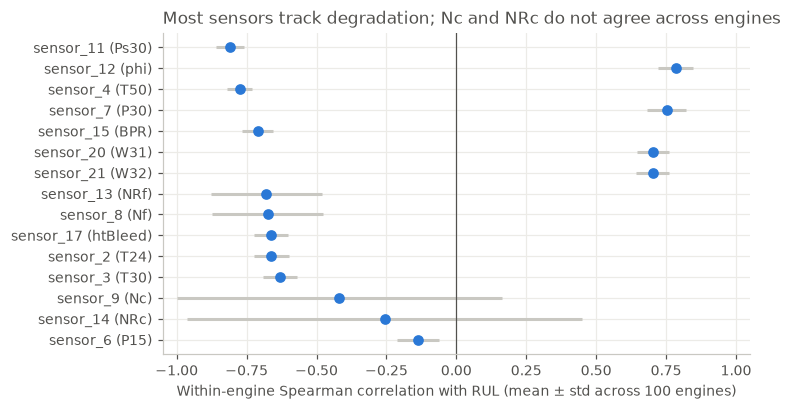

In [7]:
varying_sensors = [c for c in SENSOR_COLUMNS if train[c].nunique() > 1]

per_engine = pd.DataFrame(
    {c: {unit: spearman(g[c], g["rul"]) for unit, g in train.groupby("unit")} for c in varying_sensors}
)
summary = pd.DataFrame({"mean": per_engine.mean(), "std": per_engine.std()})
summary["symbol"] = sensor_table.loc[summary.index, "symbol"]
summary = summary.sort_values("mean", key=np.abs)

fig, ax = plt.subplots(figsize=(7, 3.8))
labels = [f"{name} ({summary.loc[name, 'symbol']})" for name in summary.index]
ax.errorbar(summary["mean"], labels, xerr=summary["std"], fmt="o", color=BLUE, ecolor=GRAY,
            elinewidth=2, markersize=6)
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_xlim(-1.05, 1.05)
ax.set_xlabel("Within-engine Spearman correlation with RUL (mean ± std across 100 engines)")
ax.set_title("Most sensors track degradation; Nc and NRc do not agree across engines", loc="left")
plt.tight_layout()

summary.iloc[::-1].round(3)

相关为负表示 RUL 变小（接近故障）时读数上升。

## 5. 退化趋势

横轴是 RUL，**从左到右越来越接近故障**。蓝线是每个 RUL 上 100 台发动机的中位数，阴影是四分位范围。只画样本不少于 20 台的 RUL 范围，避免尾部只剩几台长寿发动机造成假趋势。

画图范围 RUL <= 233


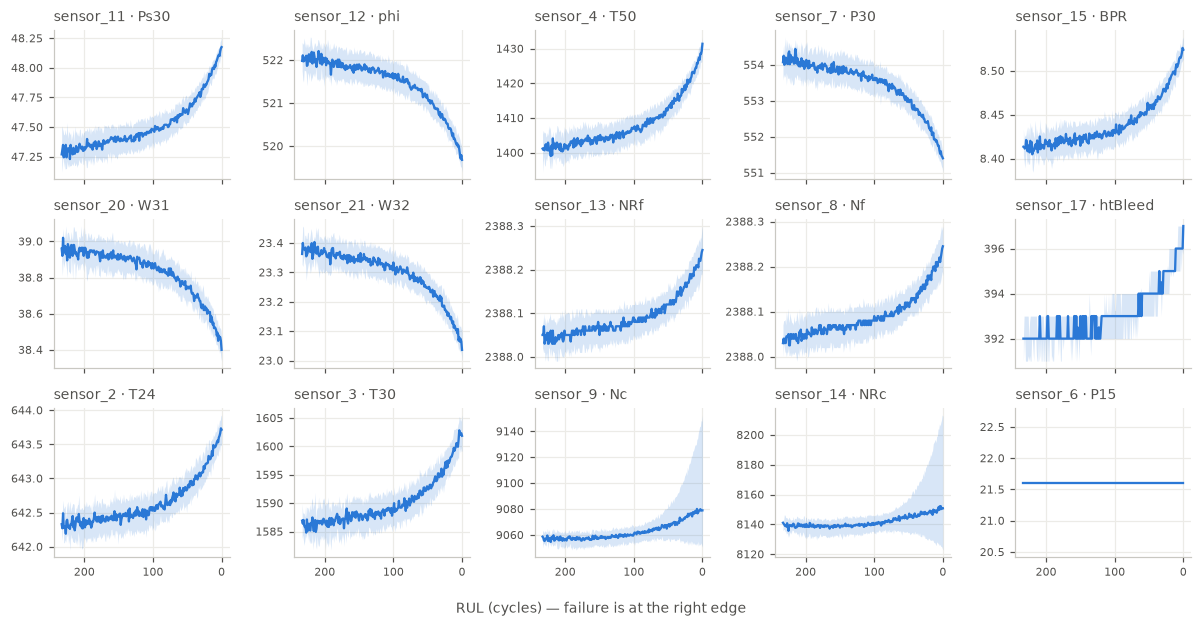

In [8]:
plot_sensors = summary.index[::-1].tolist()
engines_at_rul = train.groupby("rul")["unit"].nunique()
max_rul = engines_at_rul[engines_at_rul >= 20].index.max()
in_range = train[train["rul"] <= max_rul]

n_cols = 5
n_rows = int(np.ceil(len(plot_sensors) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(11, 1.9 * n_rows), sharex=True)
for ax, sensor in zip(axes.flat, plot_sensors):
    quantiles = in_range.groupby("rul")[sensor].quantile([0.25, 0.5, 0.75]).unstack()
    ax.fill_between(quantiles.index, quantiles[0.25], quantiles[0.75], color=BLUE, alpha=0.18, linewidth=0)
    ax.plot(quantiles.index, quantiles[0.5], color=BLUE, linewidth=1.5)
    ax.set_title(f"{sensor} · {sensor_table.loc[sensor, 'symbol']}", loc="left", fontsize=9)
    ax.tick_params(labelsize=7)
    ax.ticklabel_format(useOffset=False, axis="y")
for ax in axes.flat[len(plot_sensors):]:
    ax.set_visible(False)
axes[0, 0].invert_xaxis()  # sharex=True，所有子图一起翻转
fig.supxlabel("RUL (cycles) — failure is at the right edge", fontsize=9)
plt.tight_layout()
print("画图范围 RUL <=", max_rul)

## 6. 特殊情况：Nc（sensor_9）和 NRc（sensor_14）

这两个传感器在第 4 节的误差棒最长，说明方向不一致。这里按“末尾 20 个周期相比开头 20 个周期”把发动机分成上升和下降两组。

sensor_9: 上升 71 台，下降 29 台；净变化与寿命的 Spearman 相关 +0.284
sensor_14: 上升 57 台，下降 43 台；净变化与寿命的 Spearman 相关 +0.272
sensor_9 与 sensor_14 的 Pearson 相关: 0.963


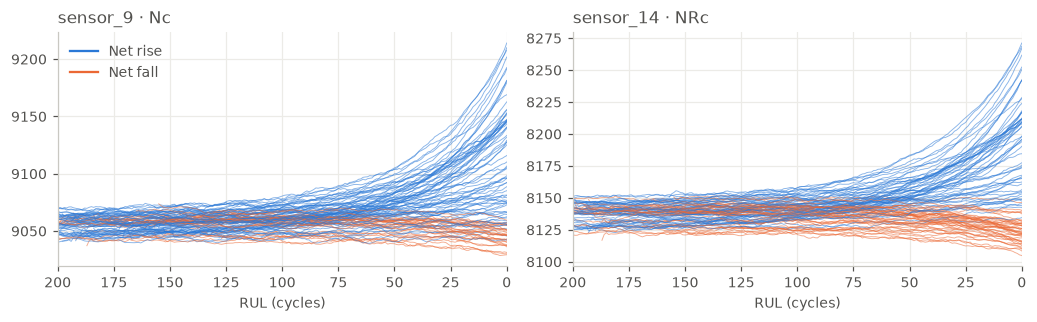

In [9]:
def net_change(sensor):
    """每台发动机最后 20 个周期的均值减去最开始 20 个周期的均值。"""
    grouped = train.sort_values("cycle").groupby("unit")[sensor]
    return grouped.apply(lambda s: s.tail(20).mean() - s.head(20).mean())


fig, axes = plt.subplots(1, 2, figsize=(9.5, 3))
for ax, sensor in zip(axes, ["sensor_9", "sensor_14"]):
    change = net_change(sensor)
    for unit, group in train.groupby("unit"):
        color = BLUE if change[unit] > 0 else ORANGE
        smooth = group[sensor].rolling(10, min_periods=1).mean()
        ax.plot(group["rul"], smooth, color=color, linewidth=0.6, alpha=0.55)
    ax.set_xlim(200, 0)
    ax.set_title(f"{sensor} · {sensor_table.loc[sensor, 'symbol']}", loc="left")
    ax.set_xlabel("RUL (cycles)")
    ax.ticklabel_format(useOffset=False, axis="y")
    print(f"{sensor}: 上升 {(change > 0).sum()} 台，下降 {(change <= 0).sum()} 台；"
          f"净变化与寿命的 Spearman 相关 {spearman(change, life):+.3f}")
handles = [plt.Line2D([], [], color=BLUE, label="Net rise"), plt.Line2D([], [], color=ORANGE, label="Net fall")]
axes[0].legend(handles=handles, frameon=False, loc="upper left")
plt.tight_layout()
print("sensor_9 与 sensor_14 的 Pearson 相关:", round(train["sensor_9"].corr(train["sensor_14"]), 3))

**发现**

- **方向确实不一致**：sensor_9 有 71 台净上升、29 台净下降；sensor_14 是 57 台对 43 台。在 RUL 大约 75 以前，两组发动机混在一起；越接近故障，两组分得越开。
- 所以它们的全局相关很弱（第 4 节均值分别为 -0.42、-0.26）。这不等于没有信息：**越接近故障，读数偏离正常值越远**，只是偏离方向因发动机而异。线性模型只能给一个固定符号的系数，很难利用这种关系；树模型或窗口特征可能利用得更好，这是待验证的假设，要在 T-006 用交叉验证检验。
- 净变化和寿命只有弱相关（约 +0.28），所以现在**不能**下结论说“上升的发动机一定更长寿”。
- 两者的 Pearson 相关高达 0.963，信息高度重复。这对线性回归的系数解释有影响，建模时要留意。

（文献里也有做法把 Nc、NRc 当作不一致的传感器去掉，比如 arXiv 2503.07854。本项目不提前删除，由 T-006 的交叉验证决定。）

## 7. 什么时候开始退化？（RUL 截顶值的依据）

把方向一致的传感器合成一个简单的退化指标，看它随 RUL 怎么变：

1. 选择第 4 节中相关均值绝对值 ≥ 0.6 的传感器。
2. 用每台发动机**最开始 20 个周期**的读数算基准均值和标准差，转成 z 分数。这些周期可以近似看作健康状态。
3. 按方向翻转符号，使“越大越接近故障”，再取平均。

这个指标只用于这里的分析，不是模型特征。

12 个传感器: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
RUL > 125 的样本占比: 0.389
RUL 125-150 区间内指标的标准差: 0.684
指标均值: RUL=0 附近 3.69 | RUL=125 附近 0.28 | RUL= 233 附近 -0.16


RUL 125-233    0.45
RUL 75-125     1.08
RUL 25-75      2.81
RUL 0-25       6.38
Name: index rise per 100 cycles, dtype: float64

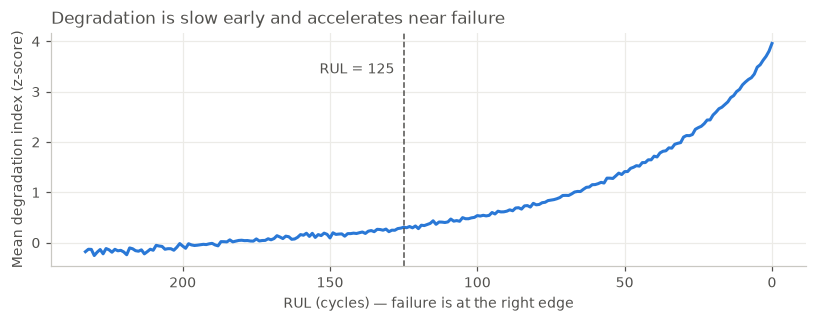

In [10]:
degrading = summary.index[summary["mean"].abs() >= 0.6].tolist()
print(len(degrading), "个传感器:", sorted(degrading, key=lambda c: int(c.split("_")[1])))

baseline = train[train["cycle"] <= 20][degrading]
direction = -np.sign(summary.loc[degrading, "mean"])  # 相关为负 = 接近故障时上升
z_scores = (train[degrading] - baseline.mean()) / baseline.std()
health_index = (z_scores * direction).mean(axis=1).rename("index")

by_rul = health_index[train["rul"] <= max_rul].groupby(train["rul"]).mean()

fig, ax = plt.subplots(figsize=(7.5, 3))
ax.plot(by_rul.index, by_rul.values, color=BLUE, linewidth=2)
ax.axvline(125, color=INK, linewidth=1, linestyle="--")
ax.annotate("RUL = 125", (125, by_rul.max() * 0.85), xytext=(-6, 0), textcoords="offset points", ha="right")
ax.invert_xaxis()
ax.set_xlabel("RUL (cycles) — failure is at the right edge")
ax.set_ylabel("Mean degradation index (z-score)")
ax.set_title("Degradation is slow early and accelerates near failure", loc="left")
plt.tight_layout()


def slope_per_100_cycles(low, high):
    """指标在 RUL 区间 [low, high] 内每接近故障 100 个周期的增量（线性拟合）。"""
    part = by_rul.loc[low:high]
    return -np.polyfit(part.index, part.values, 1)[0] * 100


slopes = pd.Series({
    f"RUL {low}-{high}": slope_per_100_cycles(low, high)
    for low, high in [(125, max_rul), (75, 125), (25, 75), (0, 25)]
}, name="index rise per 100 cycles").round(2)
within_bin_std = health_index[(train["rul"] >= 125) & (train["rul"] < 150)].std()
print("RUL > 125 的样本占比:", round((train["rul"] > 125).mean(), 3))
print("RUL 125-150 区间内指标的标准差:", round(within_bin_std, 3))
print("指标均值: RUL=0 附近", round(by_rul.loc[:5].mean(), 2), "| RUL=125 附近", round(by_rul.loc[120:130].mean(), 2),
      "| RUL=", max_rul, "附近", round(by_rul.loc[max_rul - 10:].mean(), 2))
slopes

**发现**

- **退化是逐渐加速的**。指标每接近故障 100 个周期的增量：RUL 125–233 区间约 0.45，75–125 约 1.08，25–75 约 2.81，0–25 约 6.38。
- **RUL 125 左右没有明显的“拐点”**。曲线是连续变化的，并不存在一个前面完全平坦、后面突然下降的位置。所以 125 是一个**合理的工程取值**，不是数据里算出来的物理常数。面试时不要说“数据证明退化从 125 开始”。
- **截顶的依据是信噪比**。从 RUL≈233 到 RUL≈125，指标均值只从 -0.16 变到 0.28，总共变了 0.44；而 RUL 125–150 区间内，单个样本的标准差就有 0.68。也就是说，RUL 大于 125 时，只看单个周期的读数很难分辨“还剩 200”和“还剩 150”。
- **截顶影响很大**：训练集 38.9% 的样本 RUL 大于 125，这些样本的标签都会被改写。这正是计划要比较“截顶 125”和“不截顶”的原因。

**局限**：所有发动机的寿命都不少于 128 周期，所以 RUL ≤ 127 的曲线包含全部 100 台；RUL 更大的部分只来自长寿发动机，样本构成不同，指标略低于 0（基准取自所有发动机的前 20 周期）可能和这一点有关。这个指标只是把 12 个传感器等权平均，只用来看趋势。

## 8. 结论和对建模的影响

| 发现 | 证据 | 后续怎么用 |
|---|---|---|
| 7 列完全恒定 | `setting_3` 和 sensor 1、5、10、16、18、19 只有一种取值 | T-005 起去掉。用方差筛选放进 Pipeline，只在训练折上拟合，不把列名写死 |
| `sensor_6` 基本没用 | 只有两种取值（98% 是 21.61），内部相关均值只有 -0.14 | T-005 基线去掉 |
| `setting_1`、`setting_2` 只是抖动 | 与 RUL 的相关约 0；FD001 只有一种工况 | T-005 基线去掉；以后用 FD002、FD004 时要重新评估 |
| 12 个传感器方向一致 | 内部相关绝对值 0.63–0.81，其中 10 个的标准差约 0.05–0.07，sensor_8、13 约 0.20 | 作为核心特征 |
| Nc、NRc 方向因发动机而异，且互相高度相关 | 净上升 / 下降为 71/29 和 57/43；Pearson 0.963 | 先保留，由 T-006 交叉验证决定 |
| 退化逐渐加速，RUL 高时信号弱 | 增量从 0.45 升到 6.38；RUL 大于 125 时信号小于单点噪声 | 截顶 125 有依据，但不是唯一取值；T-005、T-006 和不截顶对比 |
| 单点读数噪声大，趋势比单点更有信息 | 第 5 节曲线的抖动；第 7 节信噪比 | T-006 的滑动窗口特征（均值、标准差、斜率） |
| 测试集最短轨迹 31 周期 | 第 1 节统计 | 窗口特征必须支持不满窗口 |

**防泄漏提醒**：这里的相关分析用到了全部 100 台训练发动机的标签。如果据此硬筛特征再做交叉验证，验证折的信息就已经影响了特征选择，CV 分数会偏乐观。所以本 notebook 只用不看标签的“恒定列”判断和背景理解来决定基线特征，**是否去掉 Nc、NRc 由交叉验证决定**。其中 `sensor_6` 和 `setting_1/2` 的判断部分参考了相关性，但主要依据是它们几乎不变；T-006 可以把它们放回去做一次对照。

**类比矿用卡车（只是类比）**：设备早期状态读数差别不大，临近故障时才明显恶化；同一种读数在不同设备上的偏离方向也可能不同。这些是 FD001 仿真数据的观察，不能直接当作真实矿卡的结论。部分解释（如压气机退化使出口温度升高）只是合理推测，数据本身没有证明因果。